# 05 · NYC 311 service requests – citizen calls on the Hurricane Ida night

**Utility for the City Brain: very high** · Domain: citizen calls · Incident types: `flood`, `power_problem`, `traffic_jam`

> 6,275 real citizen calls (flooding, sewer backup, traffic signal failures) with text, time and position during Hurricane Ida, plus a normal August as reference.

| | |
|---|---|
| **Source** | NYC Open Data, 311 Service Requests `erm2-nwe9` (Socrata API) |
| **Licence** | NYC Open Data, open |
| **In this repo** | Full extract: `data/calls/nyc-311/311_ida.csv` (31 Aug – 3 Sep 2021), `311_ref.csv` (August daily counts by type), `311_types_ida.json` |
| **Get it** | https://data.cityofnewyork.us/resource/erm2-nwe9.csv?$where=created_date between '2021-08-31' and '2021-09-04' |

Legend used in the last section: **Detect** = detection rules (`brain/src/detection/`), **Graph** = graph DB (`brain/src/graph/`), **Mock** = realistic replay for mock sensors, **Scenarios** = test / demo cases, **Eval** = measure the Brain on data not used to tune it, **Score** = numbers for the scoring model.

In [1]:
import sys, json, gzip, re
from pathlib import Path
sys.path.insert(0, '..')
from cbdata import path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 160)
plt.rcParams.update({'figure.figsize': (10, 3.6), 'axes.grid': True, 'grid.alpha': .3})

## 1. What's inside

| Column | Meaning |
|---|---|
| `created_date` | When the call was made (local time) |
| `complaint_type` / `descriptor` | Category and free-text descriptor, e.g. *Sewer / Street Flooding (SJ)* |
| `borough`, `incident_zip`, `latitude`, `longitude` | Where |

`311_ref.csv` = daily counts per descriptor for August 2021 (the normal level).

In [2]:
c = pd.read_csv(path('calls/nyc-311/311_ida.csv'), parse_dates=['created_date'])
ref = pd.read_csv(path('calls/nyc-311/311_ref.csv'), parse_dates=['d'])
print(f"{len(c):,} calls"); c.descriptor.value_counts().head(10)

6,275 calls


descriptor
Sewer Backup (Use Comments) (SA)                    4030
Street Flooding (SJ)                                 767
Controller                                           661
Catch Basin Clogged/Flooding (Use Comments) (SC)     645
Excessive Water In Basement (WEFB)                   172
Name: count, dtype: int64

## 2. Ida night vs a normal day (1 Sep 18:00 → 2 Sep 06:00)

In [3]:
win = c[(c.created_date >= '2021-09-01 18:00') & (c.created_date < '2021-09-02 06:00')]
normal = ref.groupby('descriptor').n.sum() / ref.d.nunique()
t = pd.DataFrame({'August avg per day': normal, 'Ida 12 h': win.descriptor.value_counts()}).dropna()
t['x'] = (t['Ida 12 h'] / t['August avg per day']).round(1)
t.sort_values('Ida 12 h', ascending=False).head(8)

,August avg per day,Ida 12 h,x
descriptor,,,
Sewer Backup (Use Comments) (SA),57.200000,1524,26.6
Street Flooding (SJ),19.500000,471,24.2
Controller,61.366667,231,3.8
Catch Basin Clogged/Flooding (Use Comments) (SC),29.866667,153,5.1
Excessive Water In Basement (WEFB),2.800000,119,42.5


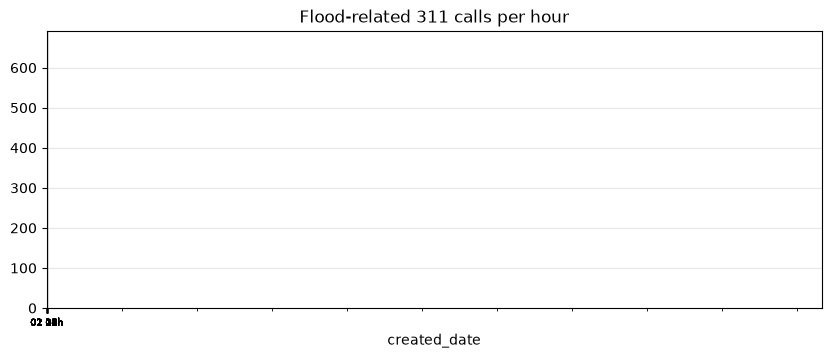

Peak hour: 2021-09-01 22:00:00 -> 659 calls


In [4]:
flood = c[c.descriptor.str.contains('Flood|Sewer Backup|Catch Basin|Basement', case=False)]
h = flood.set_index('created_date').resample('h').size().loc['2021-09-01 12:00':'2021-09-02 14:00']
ax = h.plot(kind='bar', title='Flood-related 311 calls per hour'); ax.set_xticks(range(len(h))); ax.set_xticklabels([t.strftime('%d %Hh') for t in h.index], fontsize=7); plt.show()
print('Peak hour:', h.idxmax(), '->', h.max(), 'calls')

In [5]:
gow = flood[(flood.created_date >= '2021-09-01 18:00') & (flood.latitude.between(40.66, 40.69)) & (flood.longitude.between(-74.0, -73.97))]
print('Gowanus-area flood calls on the night, first ones:'); gow.sort_values('created_date')[['created_date', 'descriptor', 'incident_zip']].head(5)

Gowanus-area flood calls on the night, first ones:


,created_date,descriptor,incident_zip
5898,2021-09-01 20:08:00,Sewer Backup (Use Comments) (SA),11231.0
5781,2021-09-01 21:21:00,Sewer Backup (Use Comments) (SA),11215.0
5716,2021-09-01 21:41:00,Sewer Backup (Use Comments) (SA),11215.0
5687,2021-09-01 21:42:00,Sewer Backup (Use Comments) (SA),11231.0
5647,2021-09-01 21:47:00,Sewer Backup (Use Comments) (SA),11215.0


The first flood calls near Gowanus came **before** the first FloodNet sensor event there (20:11 local, notebook 02): citizens and sensors confirm each other within minutes. Traffic signal failures (×4) show the storm spreading to the traffic and power domains.

## 3. What it means for the City Brain

| Use | How |
|---|---|
| **Mock** | Real messages for `brain/internal/call`: text + time + position, at real rates (peak ≈ 650 flood-related calls/hour) |
| **Detect** | "water abnormal **and** flood call" rule: sensor and calls agree in time |
| **Graph** | Calls → zone; signal failures link flood → traffic (`/chain`, `/context`) |
| **Scenarios** | The Storm-night demo: real calls replayed with the FloodNet curves, DOT speeds and outages |

**Limits:** 311 is a non-emergency line (911 calls are not public); descriptors are categories, the free-text comments are not included; NYC only.